In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import copy
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [9]:
#load dataset
DATA_PATH = "PEMS04.xls"
df = pd.read_csv(DATA_PATH)

In [10]:
print("Dataset loaded successfully!")
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
print(df.info())
print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First five rows:


,from,to,cost
0,73,5,352.6
1,5,154,347.2
2,154,263,392.9
3,263,56,440.8
4,56,96,374.6



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   from    340 non-null    int64  
 1   to      340 non-null    int64  
 2   cost    340 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 8.1 KB
None

Dataset shape:
(340, 3)


In [11]:
print("Columns:", df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Columns: ['from', 'to', 'cost']

Missing values:
from    0
to      0
cost    0
dtype: int64

Statistical summary:


,from,to,cost
count,340.000000,340.000000,340.000000
mean,149.544118,146.241176,410.300588
std,88.341793,89.092511,257.518655
min,0.000000,0.000000,3.200000
25%,71.750000,66.750000,328.775000
50%,144.500000,139.500000,367.150000
75%,229.250000,226.500000,422.300000
max,305.000000,306.000000,2712.100000


In [13]:
#Data preprocessing and graph construction
df = df[['from', 'to', 'cost']].copy()
df['from'] = pd.to_numeric(df['from'], errors='coerce')
df['to'] = pd.to_numeric(df['to'], errors='coerce')
df['cost'] = pd.to_numeric(df['cost'], errors='coerce')

# Remove missing and invalid records
df = df.dropna()
df = df[df['cost'] >= 0]

# Remove self-connections
df = df[df['from'] != df['to']]

# Remove duplicate connections
df = df.drop_duplicates(subset=['from', 'to'])
df = df.reset_index(drop=True)

print("Data cleaning completed!")
print("Number of edges:", len(df))
print("Number of unique nodes:", 
      len(set(df['from']).union(set(df['to']))))

display(df.head())

Data cleaning completed!
Number of edges: 340
Number of unique nodes: 307


,from,to,cost
0,73,5,352.6
1,5,154,347.2
2,154,263,392.9
3,263,56,440.8
4,56,96,374.6


In [15]:
G = nx.Graph()
for _, row in df.iterrows():
    G.add_edge(
        int(row['from']),
        int(row['to']),
        weight=float(row['cost'])
    )

print("Graph constructed successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is graph connected:", nx.is_connected(G))

Graph constructed successfully!
Number of nodes: 307
Number of edges: 340
Is graph connected: False


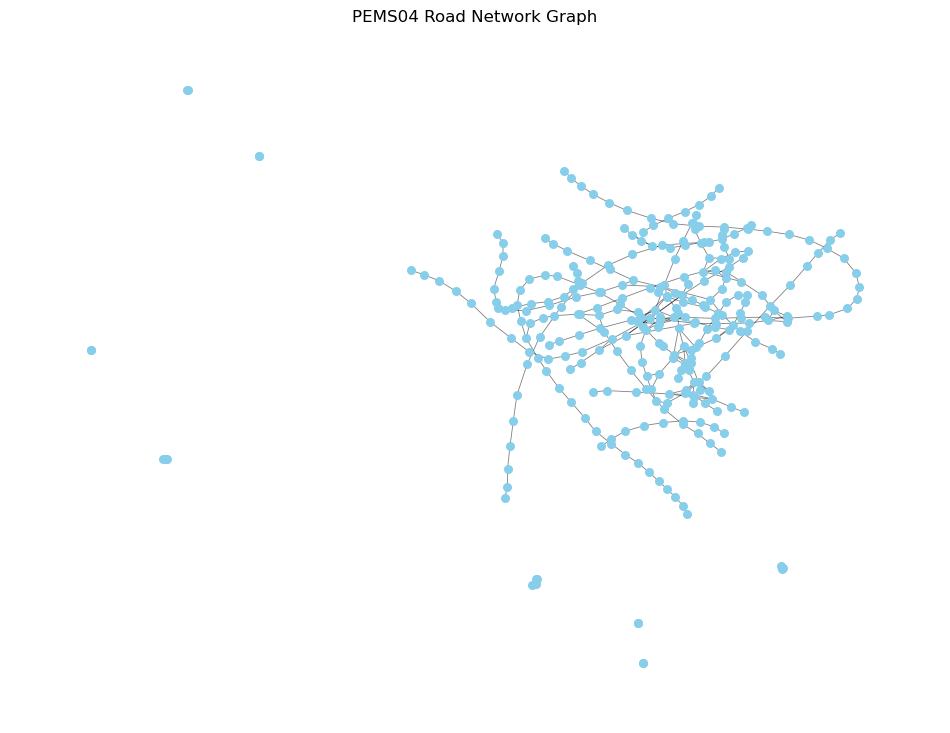

In [20]:
#visualize road work
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G, pos,
    node_size=30,
    node_color='skyblue'
)

nx.draw_networkx_edges(
    G, pos,
    width=0.6,
    alpha=0.5
)

plt.title("PEMS04 Road Network Graph")
plt.axis('off')
plt.show()

In [17]:
#Generating Rode Feautures 
nodes = sorted(G.nodes())
node_features = []
degree = dict(G.degree())
weighted_degree = {
    node: sum(data['weight'] for _, _, data in G.edges(node, data=True))
    for node in nodes
}

clustering = nx.clustering(G)
pagerank = nx.pagerank(G, weight='weight')

for node in nodes:
    node_features.append([
        degree[node],
        weighted_degree[node],
        clustering[node],
        pagerank[node]
    ])
X = torch.tensor(
    node_features,
    dtype=torch.float32
)

print("Node feature matrix created!")
print("Feature matrix shape:", X.shape)

Node feature matrix created!
Feature matrix shape: torch.Size([307, 4])


In [18]:
node_to_index = {
    node: index for index, node in enumerate(nodes)
}

index_to_node = {
    index: node for node, index in node_to_index.items()
}

print("Node mapping created!")
print("First five mappings:")

for node, index in list(node_to_index.items())[:5]:
    print(node, "->", index)

Node mapping created!
First five mappings:
0 -> 0
1 -> 1
2 -> 2
3 -> 3
4 -> 4


In [21]:
# Convert graph edges into indexed pairs
edge_pairs = []

for u, v, data in G.edges(data=True):
    edge_pairs.append([
        node_to_index[u],
        node_to_index[v],
        data['weight']
    ])

edge_pairs = np.array(edge_pairs, dtype=float)

print("Edge pairs created!")
print("Edge matrix shape:", edge_pairs.shape)
print("\nFirst five edges:")
print(edge_pairs[:5])

Edge pairs created!
Edge matrix shape: (340, 3)

First five edges:
[[ 73.    5.  352.6]
 [  5.  154.  347.2]
 [154.  263.  392.9]
 [263.   56.  440.8]
 [ 56.   96.  374.6]]


In [22]:
# Extract edge indices and costs
edge_index = edge_pairs[:, :2].astype(int)
edge_costs = edge_pairs[:, 2].astype(float)

# First split: 70% training, 30% remaining
train_edges, temp_edges, train_costs, temp_costs = train_test_split(
    edge_index,
    edge_costs,
    test_size=0.30,
    random_state=42
)
# Second split: 15% validation, 15% testing
val_edges, test_edges, val_costs, test_costs = train_test_split(
    temp_edges,
    temp_costs,
    test_size=0.50,
    random_state=42
)
print("Training edges:", len(train_edges))
print("Validation edges:", len(val_edges))
print("Testing edges:", len(test_edges))

Training edges: 238
Validation edges: 51
Testing edges: 51


In [27]:
#Construct the training adjacency matrix
num_nodes = len(nodes)
A = np.zeros((num_nodes, num_nodes), dtype=np.float32)
for u, v in train_edges:
    A[u, v] = 1
    A[v, u] = 1
A = A + np.eye(num_nodes, dtype=np.float32)
print("Adjacency matrix created!")
print("Matrix shape:", A.shape)

Adjacency matrix created!
Matrix shape: (307, 307)


In [26]:
#Normalize the adjacency matrix
degree_matrix = np.sum(A, axis=1)
D_inv_sqrt = np.diag(
    1.0 / np.sqrt(np.maximum(degree_matrix, 1e-10))
)
# Symmetric normalization
A_normalized = D_inv_sqrt @ A @ D_inv_sqrt
A_tensor = torch.tensor(
    A_normalized,
    dtype=torch.float32
)
print("Normalized adjacency matrix created!")
print("Shape:", A_tensor.shape)

Normalized adjacency matrix created!
Shape: torch.Size([307, 307])


In [29]:
# Generate Negative samples 
all_positive_edges = {
    (min(u, v), max(u, v))
    for u, v in edge_index
}
def generate_negative_edges(num_samples, num_nodes, existing_edges):
    negative_edges = set()
    while len(negative_edges) < num_samples:
        u = np.random.randint(0, num_nodes)
        v = np.random.randint(0, num_nodes)
        if u == v:
            continue
        edge = (min(u, v), max(u, v))
        if edge not in existing_edges:
            negative_edges.add(edge)
    return np.array(list(negative_edges), dtype=int)
np.random.seed(42)

train_negative_edges = generate_negative_edges(
    len(train_edges), num_nodes, all_positive_edges
)
val_negative_edges = generate_negative_edges(
    len(val_edges), num_nodes, all_positive_edges
)
test_negative_edges = generate_negative_edges(
    len(test_edges), num_nodes, all_positive_edges
)
print("Negative samples generated!")
print("Training negatives:", len(train_negative_edges))
print("Validation negatives:", len(val_negative_edges))
print("Testing negatives:", len(test_negative_edges))

Negative samples generated!
Training negatives: 238
Validation negatives: 51
Testing negatives: 51


In [32]:
#GCN Layer and Encorder
class GCNLayer(nn.Module):
    def __init__(self, input_features, output_features):
        super(GCNLayer, self).__init__()
        self.linear = nn.Linear(
            input_features,
            output_features
        )
    def forward(self, X, A):
        support = torch.matmul(A, X)
        output = self.linear(support)
        return output

class GCNEncoder(nn.Module):
    def __init__(self, input_features, hidden_features, embedding_dim):
        super(GCNEncoder, self).__init__()
        self.gcn1 = GCNLayer(
            input_features,
            hidden_features
        )
        self.gcn2 = GCNLayer(
            hidden_features,
            embedding_dim
        )
    def forward(self, X, A):
        # First graph convolution
        X = self.gcn1(X, A)
        X = F.relu(X)

        # Second graph convolution
        X = self.gcn2(X, A)
        return X

In [34]:
class GCNModel(nn.Module):
    def __init__(self, input_features, hidden_features, embedding_dim):
        super(GCNModel, self).__init__()
        self.encoder = GCNEncoder(
            input_features,
            hidden_features,
            embedding_dim
        )
        # Link prediction decoder
        self.link_decoder = nn.Sequential(
            nn.Linear(embedding_dim * 2, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, 1)
        )
        # Edge cost prediction decoder
        self.cost_decoder = nn.Sequential(
            nn.Linear(embedding_dim * 2, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, 1)
        )
    def forward(self, X, A):
        embeddings = self.encoder(X, A)
        return embeddings
    def predict_link(self, embeddings, edges):
        u = embeddings[edges[:, 0]]
        v = embeddings[edges[:, 1]]
        combined = torch.cat([u, v], dim=1)
        return self.link_decoder(combined).squeeze()

    def predict_cost(self, embeddings, edges):
        u = embeddings[edges[:, 0]]
        v = embeddings[edges[:, 1]]
        combined = torch.cat([u, v], dim=1)
        return self.cost_decoder(combined).squeeze()

In [36]:
#Initialize the Model
input_features = X.shape[1]
hidden_features = 64
embedding_dim = 32
model = GCNModel(
    input_features=input_features,
    hidden_features=hidden_features,
    embedding_dim=embedding_dim
)
print(model)

GCNModel(
  (encoder): GCNEncoder(
    (gcn1): GCNLayer(
      (linear): Linear(in_features=4, out_features=64, bias=True)
    )
    (gcn2): GCNLayer(
      (linear): Linear(in_features=64, out_features=32, bias=True)
    )
  )
  (link_decoder): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (cost_decoder): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [38]:
train_edges_tensor = torch.tensor(
    train_edges,
    dtype=torch.long)

val_edges_tensor = torch.tensor(
    val_edges,
    dtype=torch.long )

test_edges_tensor = torch.tensor(
    test_edges,
    dtype=torch.long )

train_negative_tensor = torch.tensor(
    train_negative_edges,
    dtype=torch.long )

val_negative_tensor = torch.tensor(
    val_negative_edges,
    dtype=torch.long )

test_negative_tensor = torch.tensor(
    test_negative_edges,
    dtype=torch.long )

train_cost_tensor = torch.tensor(
    np.log1p(train_costs),
    dtype=torch.float32)

val_cost_tensor = torch.tensor(
    np.log1p(val_costs),
    dtype=torch.float32)

test_cost_tensor = torch.tensor(
    np.log1p(test_costs),
    dtype=torch.float32)
print("All training tensors prepared successfully!")

All training tensors prepared successfully!


In [39]:
# Build a graph using training edges only
G_train = nx.Graph()
G_train.add_nodes_from(nodes)

for (u, v), cost in zip(train_edges, train_costs):
    original_u = index_to_node[u]
    original_v = index_to_node[v]

    G_train.add_edge(
        original_u,
        original_v,
        weight=float(cost) )

degree = dict(G_train.degree())
weighted_degree = {
    node: sum(
        data['weight']
        for _, _, data in G_train.edges(node, data=True) )
    for node in nodes
}

clustering = nx.clustering(G_train)
pagerank = nx.pagerank(G_train)
node_features = []

for node in nodes:
    node_features.append([
        degree[node],
        weighted_degree[node],
        clustering[node],
        pagerank[node]
    ])
X = torch.tensor(node_features, dtype=torch.float32)

print("Training-only node features created!")
print("Feature matrix shape:", X.shape)

Training-only node features created!
Feature matrix shape: torch.Size([307, 4])


In [41]:
def get_pair_features(embeddings, edges):
    u = embeddings[edges[:, 0]]
    v = embeddings[edges[:, 1]]
    difference = torch.abs(u - v)
    product = u * v
    return torch.cat([difference, product], dim=1)
    
def predict_link(embeddings, edges):
    pair_features = get_pair_features(embeddings, edges)
    return model.link_decoder(pair_features).reshape(-1)
    
def predict_cost(embeddings, edges):
    pair_features = get_pair_features(embeddings, edges)
    return model.cost_decoder(pair_features).reshape(-1)
print("Symmetric prediction functions ready!")

Symmetric prediction functions ready!


In [43]:
#Configutr traning process
torch.manual_seed(42)
np.random.seed(42)
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = model.to(device)
X = X.to(device)
A_tensor = A_tensor.to(device)

train_edges_tensor = train_edges_tensor.to(device)
val_edges_tensor = val_edges_tensor.to(device)

train_negative_tensor = train_negative_tensor.to(device)
val_negative_tensor = val_negative_tensor.to(device)

train_cost_tensor = train_cost_tensor.to(device)
val_cost_tensor = val_cost_tensor.to(device)

# Optimizer and loss functions
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

link_criterion = nn.BCEWithLogitsLoss()
cost_criterion = nn.MSELoss()

# Training configuration
epochs = 300
patience = 30
best_val_loss = float('inf')
patience_counter = 0

train_losses = []
val_losses = []

print("Training configuration completed!")

Using device: cpu
Training configuration completed!


In [48]:
#Train GCN Model
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    embeddings = model(X, A_tensor)
    positive_logits = predict_link(
        embeddings, train_edges_tensor
    )

    negative_logits = predict_link(
        embeddings, train_negative_tensor
    )

    # Link prediction labels
    link_logits = torch.cat([
        positive_logits,
        negative_logits
    ])

    link_labels = torch.cat([
        torch.ones_like(positive_logits),
        torch.zeros_like(negative_logits)
    ])

    link_loss = link_criterion(
        link_logits,
        link_labels
    )

    # Edge cost prediction
    predicted_costs = predict_cost(
        embeddings, train_edges_tensor
    )

    cost_loss = cost_criterion(
        predicted_costs,
        train_cost_tensor
    )

    total_loss = link_loss + 0.5 * cost_loss

    total_loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():

        val_embeddings = model(X, A_tensor)

        val_positive_logits = predict_link(
            val_embeddings, val_edges_tensor
        )

        val_negative_logits = predict_link(
            val_embeddings, val_negative_tensor
        )

        val_link_logits = torch.cat([
            val_positive_logits,
            val_negative_logits
        ])

        val_link_labels = torch.cat([
            torch.ones_like(val_positive_logits),
            torch.zeros_like(val_negative_logits)
        ])

        val_link_loss = link_criterion(
            val_link_logits,
            val_link_labels
        )

        val_predicted_costs = predict_cost(
            val_embeddings, val_edges_tensor
        )

        val_cost_loss = cost_criterion(
            val_predicted_costs,
            val_cost_tensor
        )

        val_total_loss = (
            val_link_loss + 0.5 * val_cost_loss
        )

    train_losses.append(total_loss.item())
    val_losses.append(val_total_loss.item())
    
    if val_total_loss.item() < best_val_loss:

        best_val_loss = val_total_loss.item()

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        patience_counter = 0

    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {total_loss.item():.4f} "
            f"Validation Loss: {val_total_loss.item():.4f}"
        )

    if patience_counter >= patience:
        print("Early stopping triggered!")
        break
model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)

Early stopping triggered!

Training completed!
Best validation loss: 1418.6378173828125


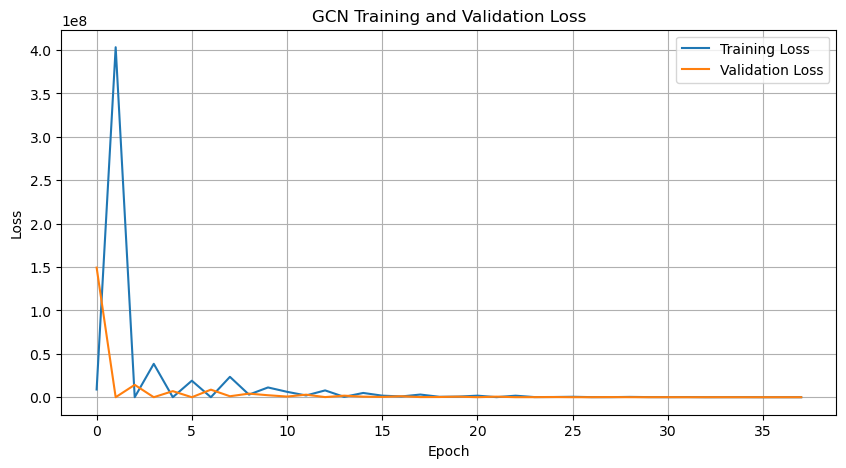

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GCN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [52]:
#Model Evaluation
test_edges_tensor = torch.tensor(
    test_edges,
    dtype=torch.long
).to(device)

test_negative_tensor = torch.tensor(
    test_negative_edges,
    dtype=torch.long
).to(device)

test_cost_tensor = torch.tensor(
    np.log1p(test_costs),
    dtype=torch.float32
).to(device)

model.eval()

with torch.no_grad():
    test_embeddings = model(X, A_tensor)

print("Testing data prepared!")
print("Test edges:", len(test_edges))
print("Negative test edges:", len(test_negative_edges))

Testing data prepared!
Test edges: 51
Negative test edges: 51


In [53]:
with torch.no_grad():
    positive_scores = torch.sigmoid(
        predict_link(test_embeddings, test_edges_tensor)
    )

    negative_scores = torch.sigmoid(
        predict_link(test_embeddings, test_negative_tensor)
    )

    y_true = np.concatenate([
        np.ones(len(positive_scores)),
        np.zeros(len(negative_scores))
    ])

    y_scores = torch.cat([
        positive_scores,
        negative_scores
    ]).cpu().numpy()
roc_auc = roc_auc_score(y_true, y_scores)
average_precision = average_precision_score(
    y_true, y_scores
)
print("LINK PREDICTION RESULTS")
print("----------------------")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")

LINK PREDICTION RESULTS
----------------------
ROC-AUC: 0.3735
Average Precision: 0.4339


In [54]:
#Evaluate edge-cost estimation
with torch.no_grad():
    predicted_log_costs = predict_cost(
        test_embeddings,
        test_edges_tensor )

predicted_costs = torch.expm1(
    predicted_log_costs
).cpu().numpy()

actual_costs = test_costs

mae = mean_absolute_error(
    actual_costs,
    predicted_costs )

rmse = np.sqrt(
    mean_squared_error(actual_costs, predicted_costs) )

print("EDGE-COST PREDICTION RESULTS")
print("----------------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

EDGE-COST PREDICTION RESULTS
----------------------------
MAE: 6375129645721368146214912.0000
RMSE: 45527532087580162242117632.0000


In [55]:
results = pd.DataFrame({
    "Actual Cost": actual_costs,
    "Predicted Cost": predicted_costs
})

display(results.head(15))

,Actual Cost,Predicted Cost
0,348.8,-9.269022e-01
1,1425.7,-4.447826e-02
2,360.2,3.462041e+06
3,344.9,6.562675e+01
4,1093.8,2.200418e+04
5,612.7,6.671590e+02
6,318.6,1.730271e+04
7,376.8,-4.447826e-02
8,424.6,-9.918635e-01
9,384.8,1.792941e+02


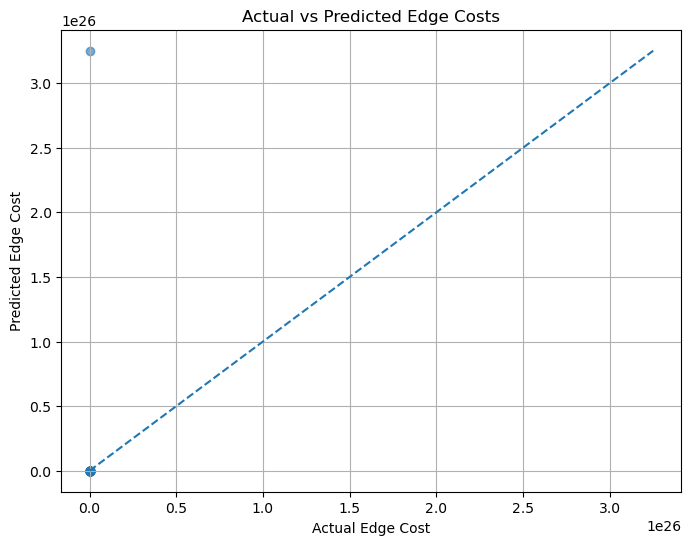

In [56]:
plt.figure(figsize=(8, 6))

plt.scatter(
    actual_costs,
    predicted_costs,
    alpha=0.6)
 
minimum = min(
    actual_costs.min(),
    predicted_costs.min() )

maximum = max(
    actual_costs.max(),
    predicted_costs.max() )

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--')

plt.xlabel("Actual Edge Cost")
plt.ylabel("Predicted Edge Cost")
plt.title("Actual vs Predicted Edge Costs")
plt.grid(True)
plt.show()

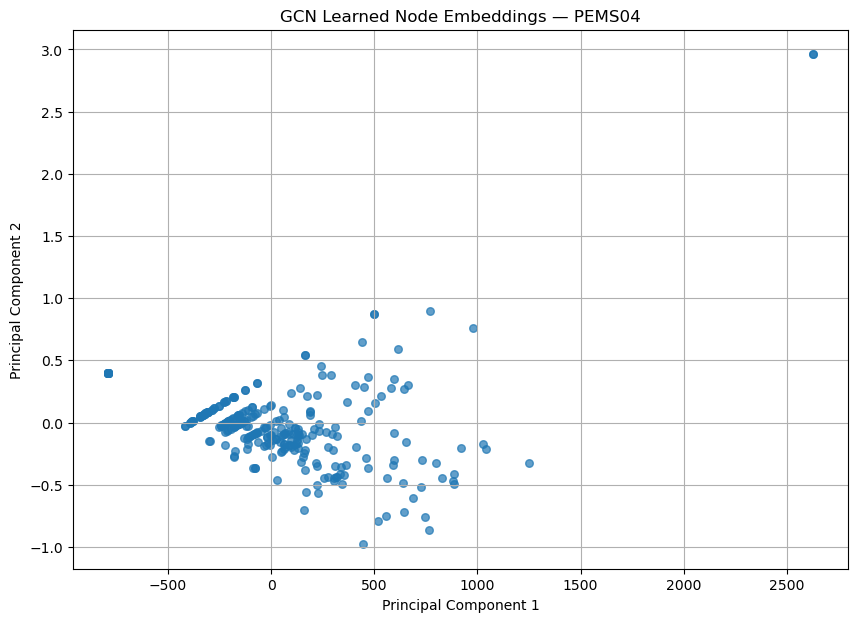

Explained variance ratio: [9.9999923e-01 6.7830393e-07]


In [59]:
#Visualize the learned node embeddings
embeddings_array = test_embeddings.detach().cpu().numpy()
pca = PCA(n_components=2, random_state=42)
embeddings_2d = pca.fit_transform(embeddings_array)
plt.figure(figsize=(10, 7))
plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1],
    alpha=0.7,
    s=30)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("GCN Learned Node Embeddings — PEMS04")
plt.grid(True)
plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_)

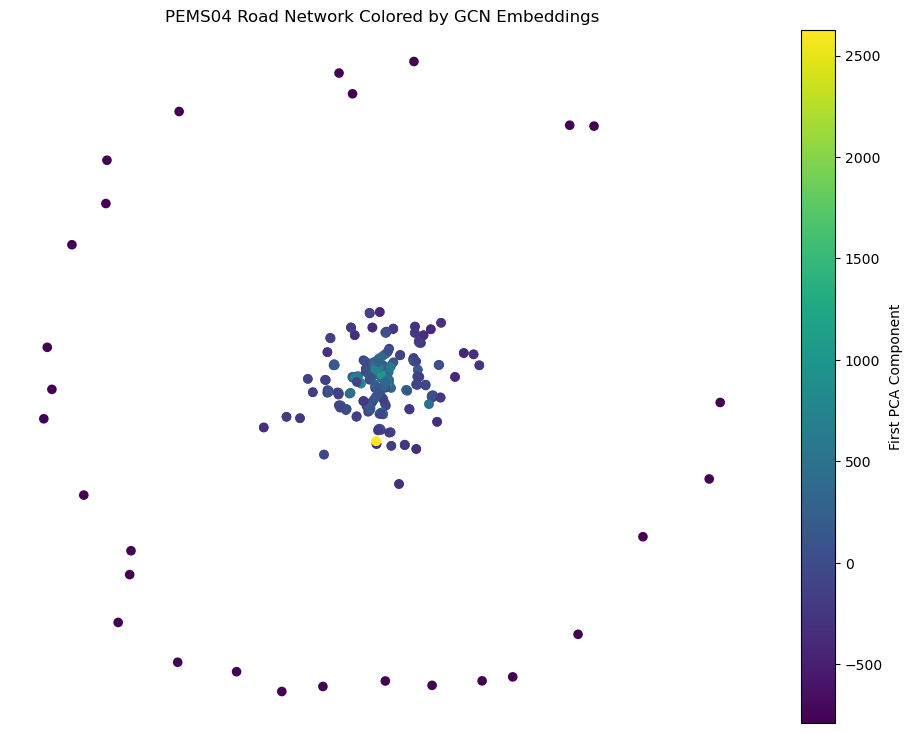

In [63]:
#Visualize node embeddings on the road network
fig, ax = plt.subplots(figsize=(12, 9))
pos = nx.spring_layout(G_train, seed=42)
node_colors = [
    embeddings_2d[node_to_index[node], 0]
    for node in G_train.nodes() ]
norm = plt.Normalize(
    vmin=min(node_colors),
    vmax=max(node_colors) )
nx.draw_networkx(
    G_train,
    pos,
    ax=ax,
    node_color=node_colors,
    cmap=plt.cm.viridis,
    vmin=min(node_colors),
    vmax=max(node_colors),
    node_size=35,
    with_labels=False,
    edge_color="gray",
    width=0.5 )
sm = plt.cm.ScalarMappable(
    cmap=plt.cm.viridis,
    norm=norm )
sm.set_array([])
fig.colorbar(
    sm,
    ax=ax,
    label="First PCA Component")

ax.set_title("PEMS04 Road Network Colored by GCN Embeddings" )
ax.axis("off")
plt.show()

In [64]:
#Identify potential missing connections
candidate_edges = generate_negative_edges(
    1000,
    num_nodes,
    all_positive_edges )

candidate_tensor = torch.tensor(
    candidate_edges,
    dtype=torch.long
).to(device)
model.eval()

with torch.no_grad():
    candidate_scores = torch.sigmoid(
        predict_link(test_embeddings, candidate_tensor)
    ).cpu().numpy()

candidate_results = pd.DataFrame({
    "From Node": [
        index_to_node[u] for u in candidate_edges[:, 0]
    ],
    "To Node": [
        index_to_node[v] for v in candidate_edges[:, 1]
    ],
    "Connection Probability": candidate_scores
})

candidate_results = candidate_results.sort_values(
    by="Connection Probability",
    ascending=False
).reset_index(drop=True)

print("Top 15 candidate connections:")
display(candidate_results.head(15))

Top 15 candidate connections:


,From Node,To Node,Connection Probability
0,182,287,1.0
1,52,150,1.0
2,57,256,1.0
3,83,174,1.0
4,285,290,1.0
5,235,271,1.0
6,50,105,1.0
7,200,211,1.0
8,51,222,1.0
9,11,275,1.0


In [65]:
embedding_columns = [
    f"Embedding_{i+1}"
    for i in range(embeddings_array.shape[1])
]
embedding_df = pd.DataFrame(
    embeddings_array,
    columns=embedding_columns
)
embedding_df.insert(0, "Node_ID", nodes)
embedding_df.to_csv(
    "PEMS04_GCN_node_embeddings.csv",
    index=False
)

print("Node embeddings exported successfully!")

Node embeddings exported successfully!


In [67]:
cost_results = pd.DataFrame({
    "From Node": [
        index_to_node[u] for u in test_edges[:, 0]
    ],
    "To Node": [
        index_to_node[v] for v in test_edges[:, 1]
    ],
    "Actual Cost": actual_costs,
    "Predicted Cost": predicted_costs})
cost_results.to_csv(
    "PEMS04_GCN_edge_cost_predictions.csv",
    index=False
)
print("Edge-cost predictions exported successfully!")

Edge-cost predictions exported successfully!


In [68]:
candidate_results.to_csv(
    "PEMS04_GCN_candidate_connections.csv",
    index=False
)

print("Candidate connections exported successfully!")

Candidate connections exported successfully!


In [69]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_features": input_features,
        "hidden_features": hidden_features,
        "embedding_dim": embedding_dim,
        "node_mapping": node_to_index
    },
    "PEMS04_GCN_model.pth"
)

print("Trained GCN model saved successfully!")

Trained GCN model saved successfully!


In [70]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Average Precision",
        "MAE",
        "RMSE"
    ],
    "Value": [
        roc_auc,
        average_precision,
        mae,
        rmse
    ]
})

display(evaluation_summary)

evaluation_summary.to_csv(
    "PEMS04_GCN_evaluation_summary.csv",
    index=False
)

print("Evaluation summary exported successfully!")

,Metric,Value
0,ROC-AUC,3.735102e-01
1,Average Precision,4.338606e-01
2,MAE,6.375130e+24
3,RMSE,4.552753e+25


Evaluation summary exported successfully!
